# Baseline Dataset Exploratory Data Analysis

This notebook explores the cleaned GSS + O*NET dataset before baseline modeling.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# Load the cleaned GSS + O*NET dataset
df = pd.read_csv("../gss2024_onet_cleaned.csv")

# Check the number of rows and columns
df.shape

(3986, 29)

## 1. Dataset Overview

In [4]:
# Preview the first five rows of the dataset
df.head()

,satjob,occ10,indus10,wrkstat,wrkslf,prestg10,sei10,realrinc,rincom16,hrs1,...,childs,region,union1,Achievement,Independence,Recognition,Relationships,Support,Working Conditions,job_zone
0,2.0,230.0,7860.0,1.0,2.0,59.0,75.5,29947.5,21.0,43.0,...,2.0,1.0,4.0,5.7525,6.08250,5.250,6.2500,3.915,5.33250,4.5
1,NaN,800.0,7280.0,5.0,2.0,60.0,76.3,16335.0,18.0,40.0,...,0.0,1.0,4.0,5.0000,5.00000,4.670,4.6700,4.670,4.50000,4.0
2,NaN,430.0,3570.0,5.0,2.0,39.0,67.7,16335.0,18.0,40.0,...,0.0,1.0,2.0,5.5000,5.29125,4.875,4.8325,4.375,5.04125,4.0
3,1.0,4760.0,4880.0,2.0,2.0,31.0,39.7,16335.0,18.0,20.0,...,0.0,1.0,4.0,3.0000,3.00000,2.670,5.0000,4.000,2.33000,2.0
4,NaN,5860.0,7860.0,5.0,2.0,32.0,35.8,16335.0,18.0,40.0,...,3.0,1.0,4.0,2.3300,2.67000,2.330,5.6700,4.330,2.50000,2.0


In [5]:
# Display all column names in the cleaned dataset
df.columns.tolist()

['satjob',
 'occ10',
 'indus10',
 'wrkstat',
 'wrkslf',
 'prestg10',
 'sei10',
 'realrinc',
 'rincom16',
 'hrs1',
 'weekswrk',
 'age',
 'sex',
 'race',
 'hispanic',
 'born',
 'educ',
 'degree',
 'marital',
 'childs',
 'region',
 'union1',
 'Achievement',
 'Independence',
 'Recognition',
 'Relationships',
 'Support',
 'Working Conditions',
 'job_zone']

In [6]:
# Check each column's data type and number of non-null values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3986 entries, 0 to 3985
Data columns (total 29 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   satjob              2782 non-null   float64
 1   occ10               3986 non-null   float64
 2   indus10             3986 non-null   float64
 3   wrkstat             3986 non-null   float64
 4   wrkslf              3986 non-null   float64
 5   prestg10            3986 non-null   float64
 6   sei10               3986 non-null   float64
 7   realrinc            3986 non-null   float64
 8   rincom16            3986 non-null   float64
 9   hrs1                3986 non-null   float64
 10  weekswrk            3986 non-null   float64
 11  age                 3986 non-null   float64
 12  sex                 3986 non-null   float64
 13  race                3986 non-null   float64
 14  hispanic            3986 non-null   float64
 15  born                3986 non-null   float64
 16  educ  

In [7]:
# Count missing values in each feature
df.isnull().sum()

satjob                1204
occ10                    0
indus10                  0
wrkstat                  0
wrkslf                   0
prestg10                 0
sei10                    0
realrinc                 0
rincom16                 0
hrs1                     0
weekswrk                 0
age                      0
sex                      0
race                     0
hispanic                 0
born                     0
educ                     0
degree                   0
marital                  0
childs                   0
region                   0
union1                   0
Achievement              0
Independence             0
Recognition              0
Relationships            0
Support                  0
Working Conditions       0
job_zone                 0
dtype: int64

In [8]:
# Check the distribution of job satisfaction values
df["satjob"].value_counts(dropna=False).sort_index()

satjob
1.0    1162
2.0    1188
3.0     294
4.0     138
NaN    1204
Name: count, dtype: int64

In [9]:
# Calculate mean, median, and mode for each feature
summary_stats = pd.DataFrame({
    "Mean": df.mean(),
    "Median": df.median(),
    "Mode": df.mode().iloc[0]
})

summary_stats

,Mean,Median,Mode
satjob,1.787203,2.000000,2.000000
occ10,4109.254641,4110.000000,4110.000000
indus10,6579.292524,7390.000000,7390.000000
wrkstat,3.062970,2.000000,1.000000
wrkslf,1.893126,2.000000,2.000000
prestg10,44.313096,44.000000,44.000000
sei10,47.628299,41.100000,41.100000
realrinc,21496.479865,16335.000000,16335.000000
rincom16,17.463372,18.000000,18.000000
hrs1,39.605620,40.000000,40.000000


## 2. Baseline Feature Distributions

In [10]:
# Calculate average and median respondent income
average_income = df["realrinc"].mean()
median_income = df["realrinc"].median()

print("Average real income:", round(average_income, 2))
print("Median real income:", round(median_income, 2))

Average real income: 21496.48
Median real income: 16335.0


In [11]:
# Check the distribution of respondent sex
df["sex"].value_counts().sort_index()

sex
1.0    1787
2.0    2199
Name: count, dtype: int64

In [12]:
# Calculate respondent sex counts and percentages
sex_breakdown = pd.DataFrame({
    "Count": df["sex"].value_counts().sort_index(),
    "Percentage": df["sex"].value_counts(normalize=True).sort_index() * 100
})

# Replace numeric codes with category labels
sex_breakdown.index = ["Male", "Female"]

sex_breakdown

,Count,Percentage
Male,1787,44.831912
Female,2199,55.168088


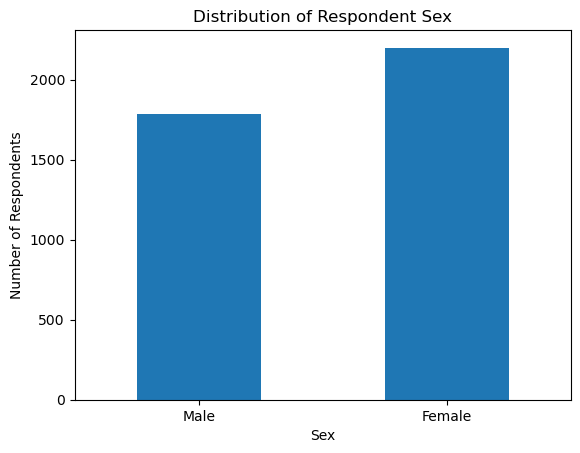

In [13]:
# Visualize the distribution of respondent sex
sex_breakdown["Count"].plot(kind="bar")

plt.title("Distribution of Respondent Sex")
plt.xlabel("Sex")
plt.ylabel("Number of Respondents")
plt.xticks(rotation=0)
plt.show()

In [14]:
# Examine the distribution of respondent age
df["age"].describe()

count    3986.000000
mean       49.001254
std        17.380320
min        18.000000
25%        35.000000
50%        48.000000
75%        63.000000
max        89.000000
Name: age, dtype: float64

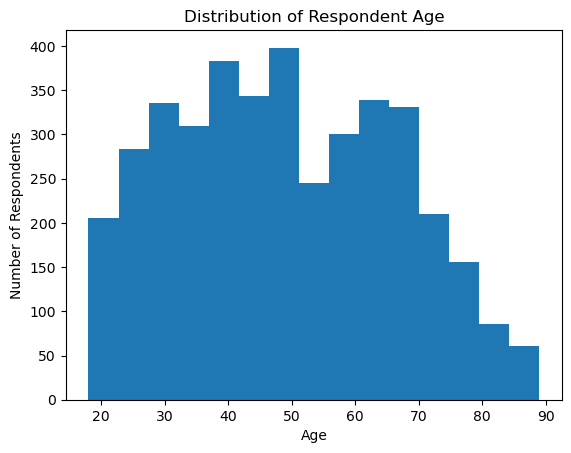

In [15]:
# Visualize the distribution of respondent age
plt.hist(df["age"], bins=15)

plt.title("Distribution of Respondent Age")
plt.xlabel("Age")
plt.ylabel("Number of Respondents")
plt.show()

In [16]:
# Examine the distribution of hours worked last week
df["hrs1"].describe()

count    3986.000000
mean       39.605620
std        10.089537
min         0.000000
25%        40.000000
50%        40.000000
75%        40.000000
max        89.000000
Name: hrs1, dtype: float64

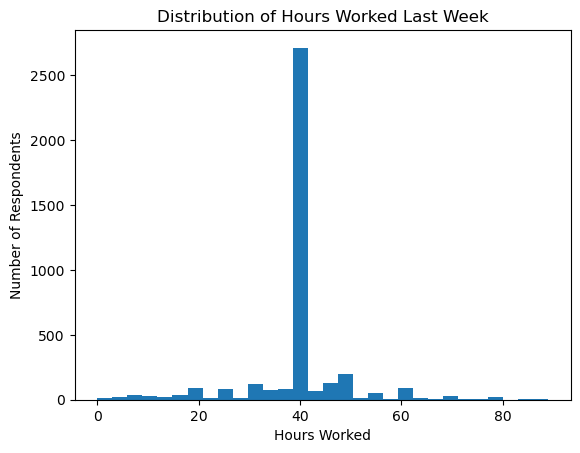

In [17]:
# Visualize the distribution of hours worked last week
plt.hist(df["hrs1"], bins=30)

plt.title("Distribution of Hours Worked Last Week")
plt.xlabel("Hours Worked")
plt.ylabel("Number of Respondents")
plt.show()

In [18]:
# Examine the distribution of inflation-adjusted family income
df["realrinc"].describe()

count     3986.000000
mean     21496.479865
std      19233.479153
min        181.500000
25%      16335.000000
50%      16335.000000
75%      19965.000000
max      97883.490870
Name: realrinc, dtype: float64

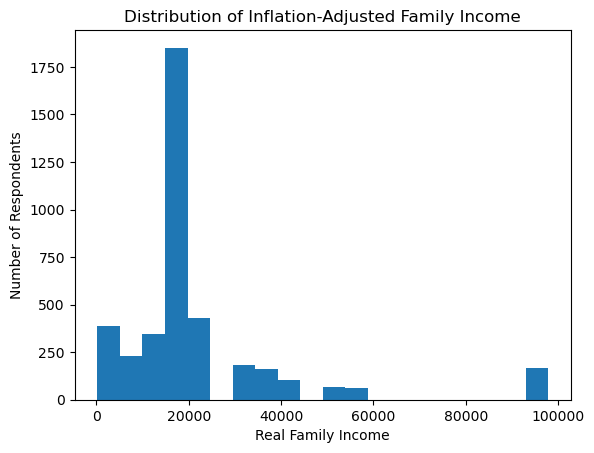

In [19]:
# Visualize the distribution of inflation-adjusted family income
plt.hist(df["realrinc"], bins=20)

plt.title("Distribution of Inflation-Adjusted Family Income")
plt.xlabel("Real Family Income")
plt.ylabel("Number of Respondents")
plt.show()

## 3. Target Variable: Job Satisfaction

In [20]:
# Calculate job satisfaction counts and percentages
satjob_breakdown = pd.DataFrame({
    "Count": df["satjob"].value_counts().sort_index(),
    "Percentage": df["satjob"].value_counts(normalize=True).sort_index() * 100
})

satjob_breakdown

,Count,Percentage
satjob,,
1.0,1162,41.768512
2.0,1188,42.703091
3.0,294,10.567937
4.0,138,4.960460


In [21]:
# Replace job satisfaction codes with their GSS category labels
satjob_breakdown.index = [
    "Very satisfied",
    "Moderately satisfied",
    "A little dissatisfied",
    "Very dissatisfied"
]

satjob_breakdown

,Count,Percentage
Very satisfied,1162,41.768512
Moderately satisfied,1188,42.703091
A little dissatisfied,294,10.567937
Very dissatisfied,138,4.960460


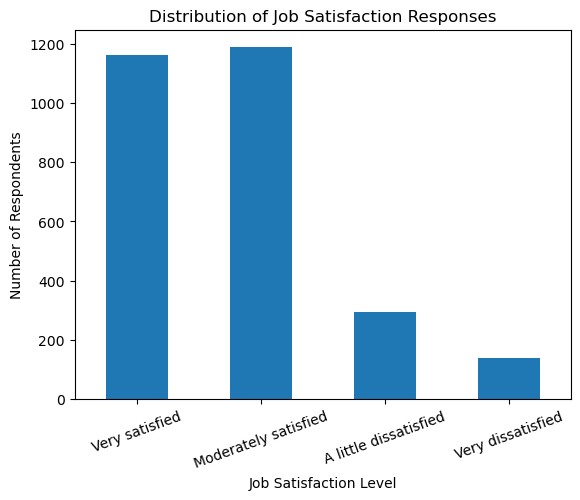

In [22]:
# Visualize the distribution of job satisfaction responses
satjob_breakdown["Count"].plot(kind="bar")

plt.title("Distribution of Job Satisfaction Responses")
plt.xlabel("Job Satisfaction Level")
plt.ylabel("Number of Respondents")
plt.xticks(rotation=20)
plt.show()

## 4. O*NET Work Value Features

In [23]:
# Select the O*NET work value features
work_value_cols = [
    "Achievement",
    "Independence",
    "Recognition",
    "Relationships",
    "Support",
    "Working Conditions"
]

# Examine descriptive statistics for the O*NET work values
df[work_value_cols].describe()

,Achievement,Independence,Recognition,Relationships,Support,Working Conditions
count,3986.000000,3986.000000,3986.000000,3986.000000,3986.000000,3986.000000
mean,3.940024,4.196299,3.434894,4.771470,4.362312,3.876723
std,1.288847,1.171549,1.213347,0.942438,0.701319,1.125822
min,1.000000,1.670000,1.000000,2.000000,2.000000,1.500000
25%,2.915000,3.000000,2.332500,4.330000,4.000000,3.056667
50%,4.000000,4.335000,3.335000,4.670000,4.334167,3.830000
75%,5.165000,5.165000,4.335000,5.330000,4.670000,4.830000
max,7.000000,6.835000,6.500000,7.000000,6.670000,6.500000


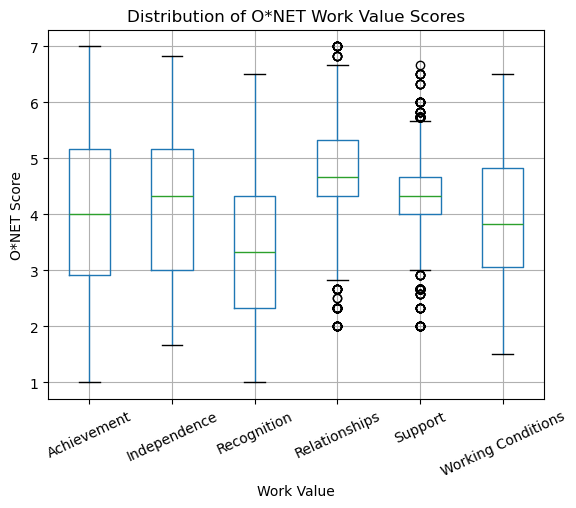

In [25]:
# Use a boxplot to compare the distributions of the O*NET work value features
# A boxplot makes it easier to compare the median, spread, range, and possible outliers
# across all six work value scores in one visualization
df[work_value_cols].boxplot()

plt.title("Distribution of O*NET Work Value Scores")
plt.xlabel("Work Value")
plt.ylabel("O*NET Score")
plt.xticks(rotation=25)
plt.show()

In [27]:
# Examine the distribution of the aggregated O*NET job zone scores
# Job zone represents the education, experience, and training required for an occupation
# During the GSS-O*NET crosswalk, job zone values were averaged across O*NET occupations
# mapped to the same Census occupation code
job_zone_breakdown = pd.DataFrame({
    "Count": df["job_zone"].value_counts().sort_index(),
    "Percentage": df["job_zone"].value_counts(normalize=True).sort_index() * 100
})

job_zone_breakdown

,Count,Percentage
job_zone,,
2.000000,1341,33.642750
2.142857,1,0.025088
2.200000,41,1.028600
2.250000,88,2.207727
2.333333,4,0.100351
2.400000,3,0.075263
2.500000,201,5.042649
2.666667,16,0.401405
2.750000,1,0.025088


In [29]:
# Examine descriptive statistics for the aggregated O*NET job zone score
# Job zone represents the education, experience, and training required for an occupation
# During the GSS-O*NET crosswalk, job zone values were averaged across O*NET occupations
# mapped to the same Census occupation code
df["job_zone"].describe()

count    3986.000000
mean        3.008807
std         0.937942
min         2.000000
25%         2.000000
50%         3.000000
75%         4.000000
max         5.000000
Name: job_zone, dtype: float64

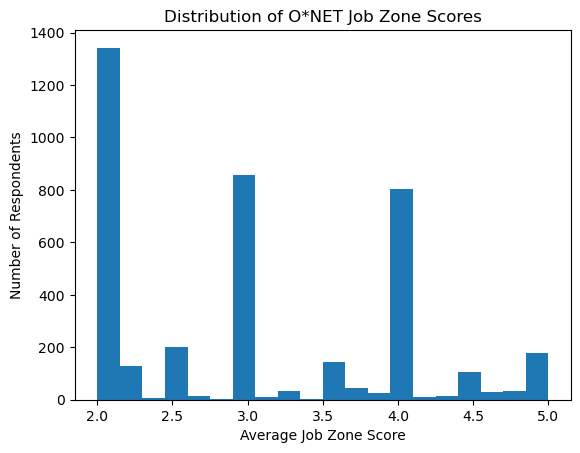

In [30]:
# Visualize the distribution of aggregated O*NET job zone scores
# A histogram is used because the crosswalk produced fractional job zone values
# by averaging across O*NET occupations mapped to the same Census occupation code
plt.hist(df["job_zone"], bins=20)

plt.title("Distribution of O*NET Job Zone Scores")
plt.xlabel("Average Job Zone Score")
plt.ylabel("Number of Respondents")
plt.show()

### Job Zone Distribution

The O*NET job zone scores are centered around 3, with a mean of approximately 3.01 and a median of 3. Most respondents are associated with occupations around Job Zones 2, 3, and 4. The large concentrations at whole-number job zones reflect the original O*NET job zone categories, while the smaller fractional values between them result from averaging multiple O*NET occupations mapped to the same Census occupation code during the crosswalk. Overall, the dataset includes respondents across different levels of occupational education, experience, and training requirements.

## 5. Relationships With Job Satisfaction

This section explores how selected baseline and O*NET occupational features relate to respondents' reported job satisfaction. These comparisons help identify patterns that may be useful when developing the baseline and person-job fit models.

In [31]:
# Compare job satisfaction levels by respondent sex
# Normalize within each sex so the values show the percentage of respondents
# in each job satisfaction category rather than just raw counts
satjob_by_sex = pd.crosstab(
    df["sex"],
    df["satjob"],
    normalize="index"
) * 100

# Replace the numeric GSS codes with descriptive labels
satjob_by_sex.index = ["Male", "Female"]

satjob_by_sex.columns = [
    "Very satisfied",
    "Moderately satisfied",
    "A little dissatisfied",
    "Very dissatisfied"
]

# Display percentages rounded to two decimal places
satjob_by_sex.round(2)

,Very satisfied,Moderately satisfied,A little dissatisfied,Very dissatisfied
Male,40.83,43.05,11.36,4.77
Female,42.55,42.42,9.91,5.12


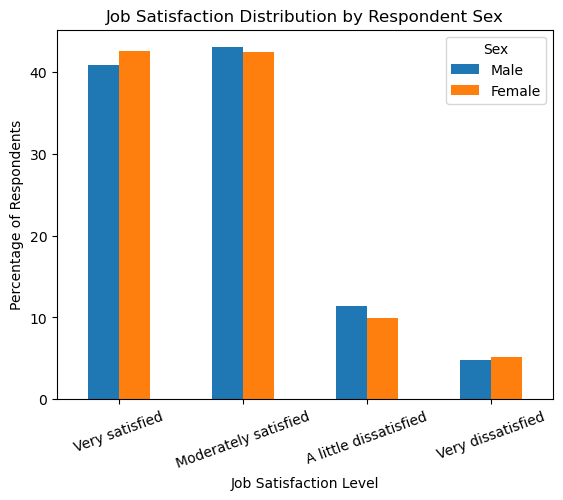

In [32]:
# Visualize job satisfaction distributions by respondent sex
# A grouped bar chart allows the satisfaction percentages for male and female
# respondents to be compared within each job satisfaction category
satjob_by_sex.T.plot(kind="bar")

plt.title("Job Satisfaction Distribution by Respondent Sex")
plt.xlabel("Job Satisfaction Level")
plt.ylabel("Percentage of Respondents")
plt.xticks(rotation=20)
plt.legend(title="Sex")
plt.show()

### Job Satisfaction by Respondent Sex

Job satisfaction patterns are fairly similar between male and female respondents. Female respondents have a slightly higher percentage reporting that they are very satisfied (42.55% compared with 40.83% for males), while male respondents have slightly higher percentages in the moderately satisfied and a little dissatisfied categories. The differences are relatively small overall, so respondent sex does not appear to show a strong descriptive relationship with job satisfaction in this initial analysis. Further modeling would be needed to determine whether sex contributes meaningfully to predicting job satisfaction when considered with other features.

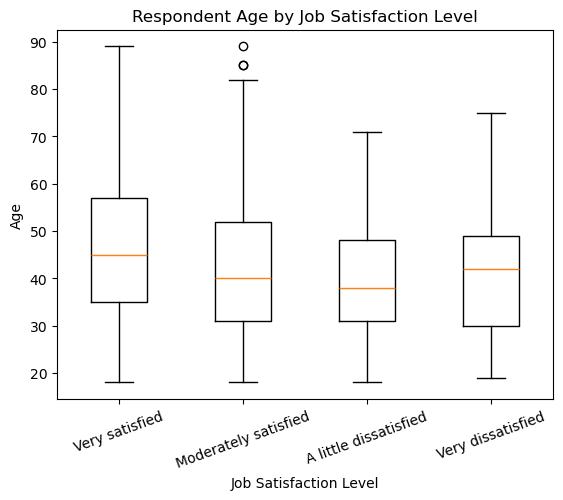

In [33]:
# Prepare age data for each job satisfaction category
age_by_satisfaction = [
    df.loc[df["satjob"] == 1, "age"],
    df.loc[df["satjob"] == 2, "age"],
    df.loc[df["satjob"] == 3, "age"],
    df.loc[df["satjob"] == 4, "age"]
]

# Visualize age distributions across job satisfaction levels
# A box plot is used because age is numeric while job satisfaction is categorical
# This allows us to compare the median, spread, and potential outliers in age
# across the four job satisfaction groups
plt.boxplot(
    age_by_satisfaction,
    tick_labels=[
        "Very satisfied",
        "Moderately satisfied",
        "A little dissatisfied",
        "Very dissatisfied"
    ]
)

plt.title("Respondent Age by Job Satisfaction Level")
plt.xlabel("Job Satisfaction Level")
plt.ylabel("Age")
plt.xticks(rotation=20)
plt.show()

### Job Satisfaction by Respondent Age

Age distributions overlap considerably across all four job satisfaction levels, although some differences are visible. Respondents who reported being very satisfied have the highest median age at approximately 45 years, while those who reported being a little dissatisfied have a lower median age at approximately 38 years. The very dissatisfied group has a slightly higher median age than both the moderately satisfied and a little dissatisfied groups. Because the age ranges overlap substantially, the relationship does not appear to be strictly linear. Further modeling can help determine whether age contributes to job satisfaction prediction when considered alongside other features.

In [34]:
# Compare real family income across job satisfaction levels
# Grouping first allows us to examine the mean, median, and sample size
# before choosing how to visualize the relationship
income_by_satisfaction = (
    df.groupby("satjob")["realrinc"]
    .agg(["count", "mean", "median"])
)

# Replace numeric job satisfaction codes with their GSS category labels
income_by_satisfaction.index = [
    "Very satisfied",
    "Moderately satisfied",
    "A little dissatisfied",
    "Very dissatisfied"
]

# Round income values to two decimal places for readability
income_by_satisfaction.round(2)

,count,mean,median
Very satisfied,1162,25117.42,16335.0
Moderately satisfied,1188,22810.45,16335.0
A little dissatisfied,294,21255.03,16335.0
Very dissatisfied,138,18789.87,16335.0


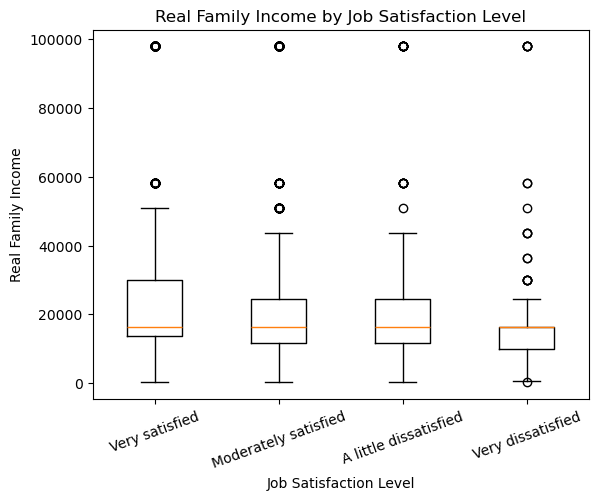

In [35]:
# Prepare real family income data for each job satisfaction category
income_groups = [
    df.loc[df["satjob"] == 1, "realrinc"],
    df.loc[df["satjob"] == 2, "realrinc"],
    df.loc[df["satjob"] == 3, "realrinc"],
    df.loc[df["satjob"] == 4, "realrinc"]
]

# Visualize real family income across job satisfaction levels
# A box plot is useful because income is highly skewed and contains high-value observations
# It allows us to compare the median, spread, and potential outliers across satisfaction groups
plt.boxplot(
    income_groups,
    tick_labels=[
        "Very satisfied",
        "Moderately satisfied",
        "A little dissatisfied",
        "Very dissatisfied"
    ]
)

plt.title("Real Family Income by Job Satisfaction Level")
plt.xlabel("Job Satisfaction Level")
plt.ylabel("Real Family Income")
plt.xticks(rotation=20)
plt.show()

### Job Satisfaction by Real Family Income

Real family income shows some differences across job satisfaction levels, although the distributions overlap considerably. All four satisfaction groups have the same median income of $16,335, while the mean income decreases from approximately $25,117 among very satisfied respondents to approximately $18,790 among very dissatisfied respondents. The box plot also shows several high-income observations across the satisfaction groups, which helps explain why the means are higher than the medians. Overall, income may have some relationship with job satisfaction, but the substantial overlap suggests that income alone does not clearly distinguish the satisfaction groups.

In [36]:
# Compare hours worked last week across job satisfaction levels
# Grouping first allows us to compare the mean, median, and sample size
# for each satisfaction category before visualizing the distributions
hours_by_satisfaction = (
    df.groupby("satjob")["hrs1"]
    .agg(["count", "mean", "median"])
)

# Replace numeric job satisfaction codes with their GSS category labels
hours_by_satisfaction.index = [
    "Very satisfied",
    "Moderately satisfied",
    "A little dissatisfied",
    "Very dissatisfied"
]

# Round values to two decimal places for readability
hours_by_satisfaction.round(2)

,count,mean,median
Very satisfied,1162,39.95,40.0
Moderately satisfied,1188,39.29,40.0
A little dissatisfied,294,38.65,40.0
Very dissatisfied,138,37.92,40.0


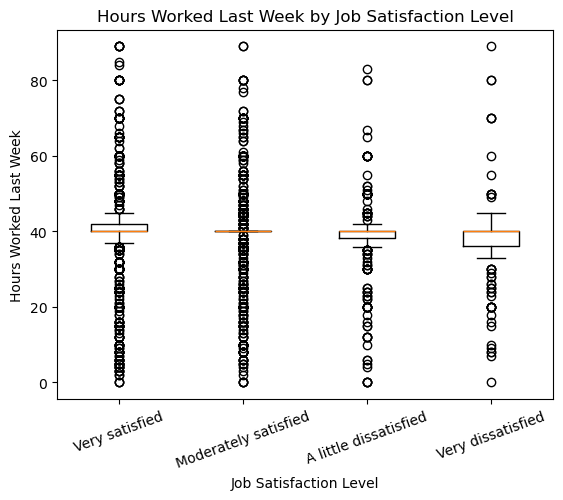

In [37]:
# Visualize hours worked last week across job satisfaction levels
# A box plot is used because hours worked is a numeric variable and
# we want to compare its distribution across the four satisfaction groups

hours_data = [
    df.loc[df["satjob"] == 1, "hrs1"],
    df.loc[df["satjob"] == 2, "hrs1"],
    df.loc[df["satjob"] == 3, "hrs1"],
    df.loc[df["satjob"] == 4, "hrs1"]
]

plt.boxplot(
    hours_data,
    tick_labels=[
        "Very satisfied",
        "Moderately satisfied",
        "A little dissatisfied",
        "Very dissatisfied"
    ]
)

plt.title("Hours Worked Last Week by Job Satisfaction Level")
plt.xlabel("Job Satisfaction Level")
plt.ylabel("Hours Worked Last Week")
plt.xticks(rotation=20)
plt.show()

**Observation:** The median number of hours worked last week is 40 hours across all four job satisfaction levels. The distributions are concentrated around 40 hours, although each satisfaction group contains respondents who worked substantially fewer or more hours. The mean decreases slightly from 39.95 hours among very satisfied respondents to 37.92 hours among very dissatisfied respondents, but the distributions overlap considerably. Based on this initial comparison, hours worked alone does not appear to show a strong relationship with job satisfaction.

In [38]:
# Compare average O*NET work value scores across job satisfaction levels
# This helps explore whether respondents in different satisfaction groups
# are linked to occupations with different work value characteristics

work_values_by_satisfaction = (
    df.groupby("satjob")[work_value_cols]
      .mean()
)

# Replace numeric job satisfaction codes with their GSS category labels
work_values_by_satisfaction.index = [
    "Very satisfied",
    "Moderately satisfied",
    "A little dissatisfied",
    "Very dissatisfied"
]

# Round scores to two decimal places for readability
work_values_by_satisfaction.round(2)

,Achievement,Independence,Recognition,Relationships,Support,Working Conditions
Very satisfied,4.06,4.29,3.54,4.84,4.35,3.97
Moderately satisfied,3.87,4.15,3.37,4.75,4.34,3.81
A little dissatisfied,3.78,4.05,3.27,4.72,4.31,3.72
Very dissatisfied,3.57,3.81,3.12,4.74,4.21,3.49


**Observation:** Several O*NET work value scores show a noticeable pattern across job satisfaction levels. Average Achievement, Independence, Recognition, and Working Conditions scores generally decrease as job satisfaction decreases. For example, the average Achievement score decreases from 4.06 for very satisfied respondents to 3.57 for very dissatisfied respondents. Support and Relationships vary less across the satisfaction groups. These initial results suggest that some occupational work value characteristics may be related to job satisfaction, although this analysis does not yet measure person-job fit or establish whether these differences are statistically significant.

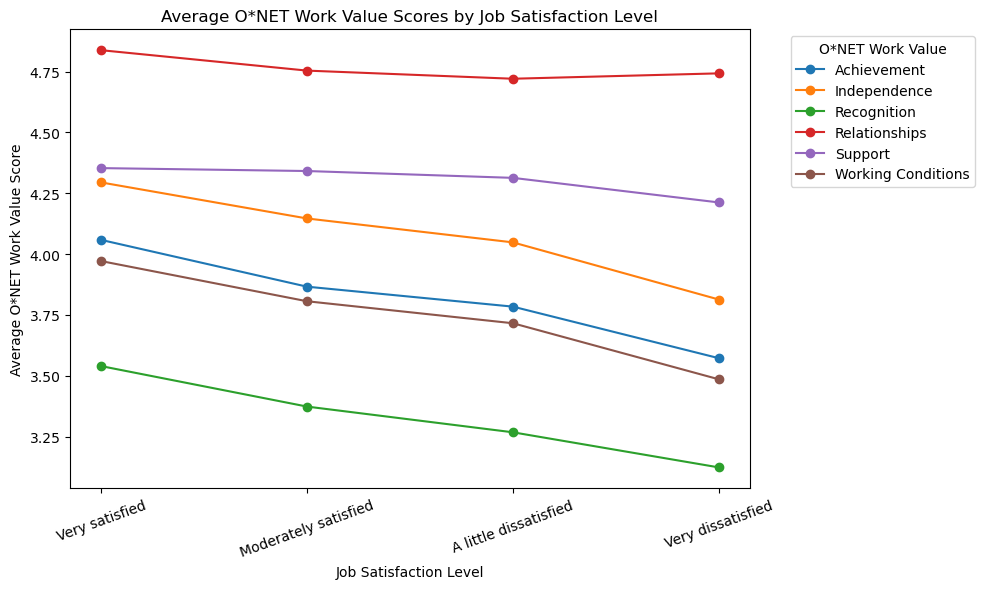

In [39]:
# Visualize average O*NET work value scores across job satisfaction levels
# A line plot is used to compare how the average score for each work value
# changes across the ordered job satisfaction categories

work_values_by_satisfaction.plot(
    kind="line",
    marker="o",
    figsize=(10, 6)
)

plt.title("Average O*NET Work Value Scores by Job Satisfaction Level")
plt.xlabel("Job Satisfaction Level")
plt.ylabel("Average O*NET Work Value Score")
plt.xticks(
    range(len(work_values_by_satisfaction.index)),
    work_values_by_satisfaction.index,
    rotation=20
)
plt.legend(title="O*NET Work Value", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Observation:** Achievement, Independence, Recognition, and Working Conditions show a consistent downward pattern as job satisfaction decreases. Respondents who reported being very satisfied are linked to occupations with the highest average scores for each of these work values, while very dissatisfied respondents are linked to occupations with the lowest average scores. Support shows a smaller decrease across the satisfaction levels, while Relationships remains relatively stable. This suggests that some O*NET occupational characteristics may be more strongly associated with job satisfaction than others. However, these are occupation-level averages from the GSS-O*NET crosswalk and do not yet represent individual person-job fit or establish a causal relationship.

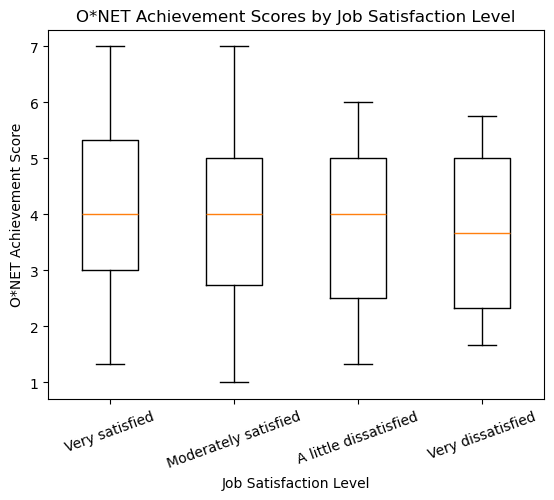

In [40]:
# Compare the distribution of O*NET Achievement scores across job satisfaction levels
# A box plot is used because Achievement is numeric and we want to see
# differences in the median, spread, and potential outliers across satisfaction groups

achievement_data = [
    df.loc[df["satjob"] == 1, "Achievement"],
    df.loc[df["satjob"] == 2, "Achievement"],
    df.loc[df["satjob"] == 3, "Achievement"],
    df.loc[df["satjob"] == 4, "Achievement"]
]

plt.boxplot(
    achievement_data,
    tick_labels=[
        "Very satisfied",
        "Moderately satisfied",
        "A little dissatisfied",
        "Very dissatisfied"
    ]
)

plt.title("O*NET Achievement Scores by Job Satisfaction Level")
plt.xlabel("Job Satisfaction Level")
plt.ylabel("O*NET Achievement Score")
plt.xticks(rotation=20)
plt.show()

**Observation:** The Achievement score distributions overlap considerably across all four job satisfaction levels. The median Achievement score is similar for the very satisfied, moderately satisfied, and a little dissatisfied groups, while the very dissatisfied group has a somewhat lower median. Although the earlier mean comparison showed Achievement scores decreasing as job satisfaction decreased, this box plot shows that the distributions are not clearly separated. This suggests that Achievement may have some relationship with job satisfaction, but Achievement alone is unlikely to distinguish satisfaction levels.

In [41]:
# Compare aggregated O*NET job zone scores across job satisfaction levels
# Job zone represents the education, experience, and training typically
# required for an occupation

job_zone_by_satisfaction = (
    df.groupby("satjob")["job_zone"]
      .agg(["count", "mean", "median"])
)

# Replace numeric job satisfaction codes with their GSS category labels
job_zone_by_satisfaction.index = [
    "Very satisfied",
    "Moderately satisfied",
    "A little dissatisfied",
    "Very dissatisfied"
]

# Round values to two decimal places for readability
job_zone_by_satisfaction.round(2)

,count,mean,median
Very satisfied,1162,3.09,3.0
Moderately satisfied,1188,2.98,3.0
A little dissatisfied,294,2.88,3.0
Very dissatisfied,138,2.74,2.1


**Observation:** Average O*NET Job Zone scores decrease as job satisfaction decreases, from 3.09 among very satisfied respondents to 2.74 among very dissatisfied respondents. The first three satisfaction groups have a median Job Zone score of 3.0, while the very dissatisfied group has a lower median of 2.1. This suggests that respondents linked to occupations with higher education, experience, and training requirements may report somewhat higher job satisfaction. However, the differences are descriptive and do not establish that Job Zone requirements cause differences in job satisfaction.

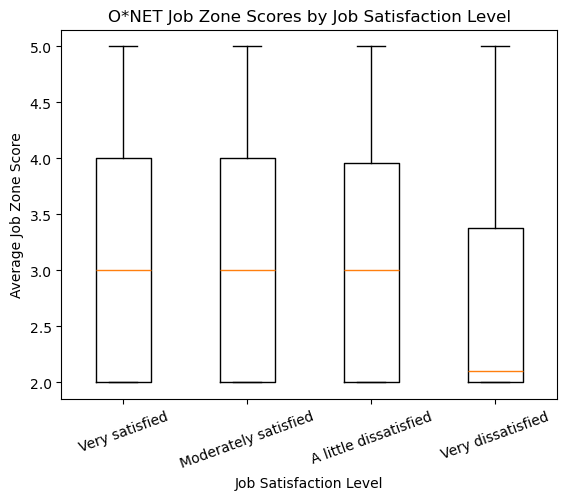

In [42]:
# Compare the distribution of aggregated O*NET job zone scores
# across job satisfaction levels
# A box plot is used to compare the median, spread, and overlap between
# satisfaction groups rather than relying only on their average scores

job_zone_data = [
    df.loc[df["satjob"] == 1, "job_zone"],
    df.loc[df["satjob"] == 2, "job_zone"],
    df.loc[df["satjob"] == 3, "job_zone"],
    df.loc[df["satjob"] == 4, "job_zone"]
]

plt.boxplot(
    job_zone_data,
    tick_labels=[
        "Very satisfied",
        "Moderately satisfied",
        "A little dissatisfied",
        "Very dissatisfied"
    ]
)

plt.title("O*NET Job Zone Scores by Job Satisfaction Level")
plt.xlabel("Job Satisfaction Level")
plt.ylabel("Average Job Zone Score")
plt.xticks(rotation=20)
plt.show()

**Observation:** The Job Zone distributions overlap substantially across the four job satisfaction levels. The very satisfied, moderately satisfied, and a little dissatisfied groups have similar distributions and a median Job Zone score of 3.0. The very dissatisfied group stands out with a lower median of approximately 2.1 and a lower upper quartile. Although the average Job Zone score decreased as job satisfaction decreased, the box plot shows that most of the difference is concentrated in the very dissatisfied group rather than showing a strong separation across all four categories.

In [43]:
# Examine correlations among selected numeric baseline and O*NET features
# This helps identify features that may contain similar information
# before they are used together in later modeling

correlation_cols = [
    "age",
    "realrinc",
    "hrs1",
    "prestg10",
    "sei10",
    "Achievement",
    "Independence",
    "Recognition",
    "Relationships",
    "Support",
    "Working Conditions",
    "job_zone"
]

correlation_matrix = df[correlation_cols].corr()

# Round correlations to two decimal places for readability
correlation_matrix.round(2)

,age,realrinc,hrs1,prestg10,sei10,Achievement,Independence,Recognition,Relationships,Support,Working Conditions,job_zone
age,1.00,0.01,-0.02,0.11,0.11,0.09,0.09,0.10,-0.01,0.08,0.12,0.08
realrinc,0.01,1.00,0.21,0.29,0.39,0.33,0.32,0.37,-0.00,0.15,0.37,0.33
hrs1,-0.02,0.21,1.00,0.05,0.07,0.06,0.09,0.08,-0.05,0.14,0.11,0.04
prestg10,0.11,0.29,0.05,1.00,0.82,0.79,0.71,0.79,0.24,0.31,0.80,0.77
sei10,0.11,0.39,0.07,0.82,1.00,0.85,0.78,0.88,0.23,0.26,0.87,0.87
Achievement,0.09,0.33,0.06,0.79,0.85,1.00,0.91,0.95,0.34,0.18,0.92,0.86
Independence,0.09,0.32,0.09,0.71,0.78,0.91,1.00,0.90,0.26,0.21,0.90,0.77
Recognition,0.10,0.37,0.08,0.79,0.88,0.95,0.90,1.00,0.28,0.25,0.94,0.85
Relationships,-0.01,-0.00,-0.05,0.24,0.23,0.34,0.26,0.28,1.00,-0.05,0.22,0.31
Support,0.08,0.15,0.14,0.31,0.26,0.18,0.21,0.25,-0.05,1.00,0.35,0.09


**Observation:** Several O*NET work value features are strongly positively correlated with one another. Achievement, Independence, Recognition, and Working Conditions have correlations of approximately 0.90 or higher in several pairwise comparisons. These variables are also strongly correlated with occupational measures such as `sei10`, `prestg10`, and `job_zone`. In contrast, Relationships and Support generally have weaker correlations with the other O*NET work values. These results suggest that some of the occupational features contain overlapping information, which may need to be considered during feature selection and model interpretation.

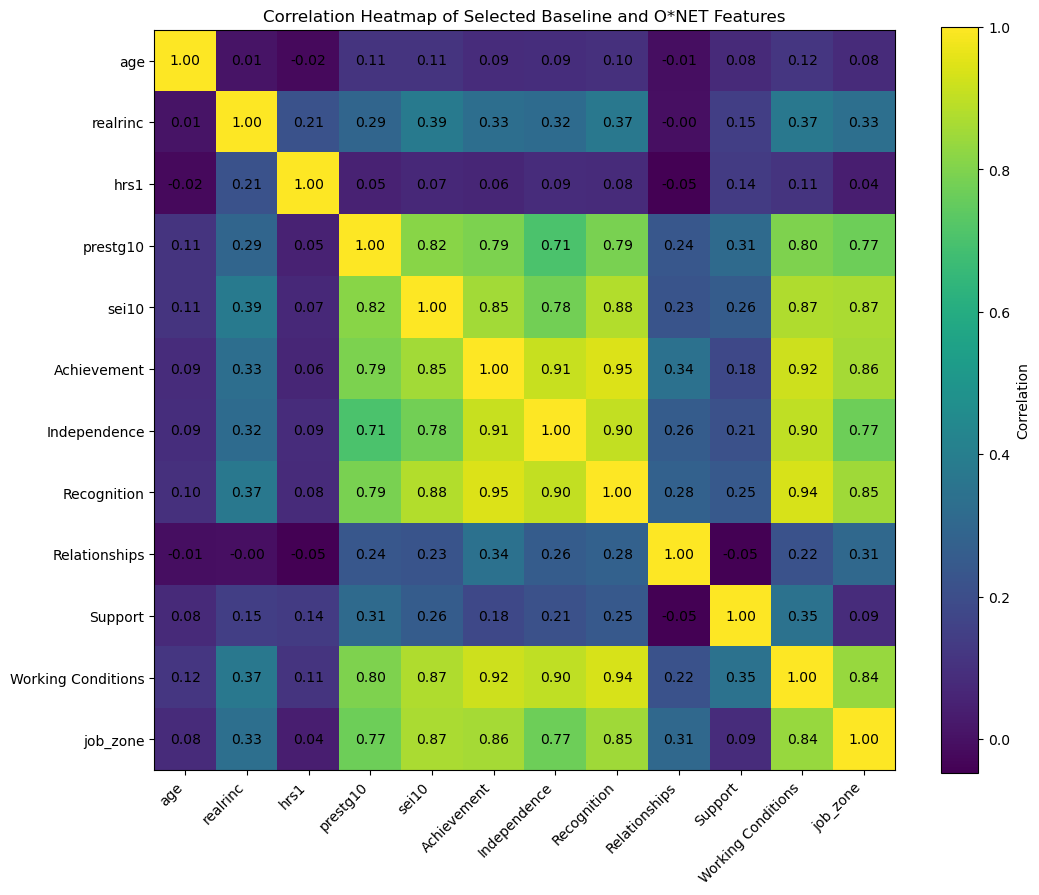

In [44]:
# Visualize correlations among selected baseline and O*NET features
# A heatmap makes it easier to identify clusters of strongly related
# variables than the numeric correlation matrix alone

fig, ax = plt.subplots(figsize=(11, 9))

heatmap = ax.imshow(correlation_matrix)

# Add variable names to both axes
ax.set_xticks(range(len(correlation_cols)))
ax.set_xticklabels(correlation_cols, rotation=45, ha="right")

ax.set_yticks(range(len(correlation_cols)))
ax.set_yticklabels(correlation_cols)

# Display each correlation coefficient inside its cell
for i in range(len(correlation_cols)):
    for j in range(len(correlation_cols)):
        ax.text(
            j,
            i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.colorbar(heatmap, label="Correlation")
plt.title("Correlation Heatmap of Selected Baseline and O*NET Features")
plt.tight_layout()
plt.show()

**Observation:** The heatmap shows a clear cluster of strong positive correlations among several occupational features. Achievement, Independence, Recognition, and Working Conditions are strongly related to one another and are also associated with `prestg10`, `sei10`, and `job_zone`. Relationships and Support are less strongly connected to this cluster, while age and hours worked have relatively weak correlations with most of the selected features. This pattern suggests that several occupational variables may capture overlapping information, which should be considered when interpreting the later models.

## 5. Key Findings

- Job satisfaction is not evenly distributed. Most respondents reported being either very satisfied (41.77%) or moderately satisfied (42.70%), while fewer reported being a little dissatisfied (10.57%) or very dissatisfied (4.96%).
- Respondents ranged from 18 to 89 years old, with an average age of about 49.
- Hours worked last week were heavily concentrated around 40 hours. The median was 40 hours across all four job satisfaction groups.
- Real family income was right-skewed. The median income was the same across all four satisfaction groups, while average income was highest for the very satisfied group and lowest for the very dissatisfied group.
- Job satisfaction patterns were fairly similar between male and female respondents.
- Achievement, Independence, Recognition, and Working Conditions generally had lower average O*NET scores as job satisfaction decreased.
- Relationships and Support showed smaller differences across job satisfaction levels than the other O*NET work values.
- Average O*NET Job Zone scores were lower for respondents with lower job satisfaction, with the lowest average appearing among very dissatisfied respondents.
- Several O*NET features were highly correlated with one another, especially Achievement, Independence, Recognition, and Working Conditions. This should be considered when selecting features for modeling.

## 6. Modeling Considerations and Next Steps

The job satisfaction target is imbalanced, with most respondents in the two satisfied categories. This should be considered when evaluating the classification models rather than relying only on accuracy.

Several O*NET work value features are also highly correlated with one another, which could create redundant information in the models.

The next stage of the project can use these findings to evaluate the baseline feature set and compare it with models that include the O*NET person-job fit features. This will help determine whether the fit-related features improve job satisfaction prediction beyond the baseline demographic, economic, and employment features.